# 03 — Handling class imbalance: weighted loss vs post-hoc logit adjustment

Two-thirds of the training images are moles (NV), and the official metric (balanced accuracy) weights all seven classes
equally. The plain baseline (notebook 01) learns the majority class well and misses minority classes, including melanoma.

Two fixes, each changing **one thing** relative to the baseline (ResNet-50, 224 px, 30 epochs):

1. **Weighted cross-entropy** (retrain): loss of class *i* multiplied by wᵢ = N / nᵢ — Gessert et al.'s choice.
   `python train_classifier.py --run-name resnet50_wce --loss-weighting inverse --fold k`
2. **Post-hoc logit adjustment** (no retraining; Menon et al., ICLR 2021): predict
   argmax log p(y|x) − τ·log πᵧ, with π the class prior of the fold's training split. One τ is chosen by mean CV balanced
   accuracy, **never on the test set**. `python posthoc_logit_adjustment.py resnet50_ce`

**Reproduce:** `salloc ... srun ... bash slurm/run_loss_weighting_node.sh` (10 runs, ~18 min), then the adjustment (CPU, seconds).

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HWX_DIR = Path.cwd() if (Path.cwd() / "isic").is_dir() else Path.cwd().parent
sys.path.insert(0, str(HWX_DIR))
from isic import analysis as A
from isic.data import CLASSES

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

# Results below are loaded from results/. Set RUN_TRAINING = True (on a GPU node) to re-create
# one fold of this version first; the full 5-fold runs use the slurm/ drivers listed above.
RUN_TRAINING = False

def run(cmd):
    print("$", cmd, flush=True)
    subprocess.run(cmd, shell=True, check=True, cwd=HWX_DIR)

In [2]:
if RUN_TRAINING:   # one fold of each variant, ~6 min each on an A100
    run("python train_classifier.py --run-name resnet50_ce --fold 0")
    run("python train_classifier.py --run-name resnet50_wce --loss-weighting inverse --fold 0")
    run("python posthoc_logit_adjustment.py resnet50_ce")
    run("python posthoc_logit_adjustment.py resnet50_wce")

## 1. Results on the official test set (mean ± std over 5 fold models)

In [3]:
runs = ["resnet50_ce", "resnet50_wce", "resnet50_ce_la", "resnet50_wce_la"]
names = ["plain CE (baseline)", "weighted CE", "plain CE + logit adjustment", "weighted CE + logit adjustment"]
display(A.summary(runs, names=names))
print("selected tau:", {n: A.tau(r)["selected_tau"] for r, n in zip(runs, names) if A.tau(r)})

,bal_acc,acc,f1,auc,mel_sens,mel_spec,ensemble_bal_acc,n_folds
plain CE (baseline),0.724 ± 0.012,0.834 ± 0.012,0.740 ± 0.015,0.966 ± 0.002,0.599 ± 0.032,0.953 ± 0.011,0.766,5
weighted CE,0.773 ± 0.011,0.810 ± 0.032,0.736 ± 0.027,0.965 ± 0.005,0.674 ± 0.042,0.929 ± 0.020,0.827,5
plain CE + logit adjustment,0.786 ± 0.013,0.776 ± 0.068,0.695 ± 0.053,0.958 ± 0.006,0.678 ± 0.015,0.912 ± 0.035,0.843,5
weighted CE + logit adjustment,0.785 ± 0.013,0.770 ± 0.053,0.705 ± 0.051,0.960 ± 0.007,0.695 ± 0.034,0.901 ± 0.032,0.853,5


selected tau: {'plain CE + logit adjustment': 1.6, 'weighted CE + logit adjustment': 0.5}


In [4]:
# Paired against the plain baseline (same folds, same seed). AUC barely moves: the fixes change the decision rule, not the features.
A.paired_table(runs[1:], "resnet50_ce", names=names[1:])

,cv_bal_acc,cv_mel_sens,cv_auc,test_bal_acc,test_mel_sens,test_auc
weighted CE,+0.027 ± 0.013 (5/5),+0.040 ± 0.123 (3/5),-0.002 ± 0.005 (2/5),+0.050 ± 0.016 (5/5),+0.075 ± 0.068 (5/5),-0.001 ± 0.006 (2/5)
plain CE + logit adjustment,+0.028 ± 0.014 (5/5),+0.059 ± 0.042 (5/5),-0.012 ± 0.004 (0/5),+0.063 ± 0.008 (5/5),+0.080 ± 0.019 (5/5),-0.008 ± 0.005 (0/5)
weighted CE + logit adjustment,+0.030 ± 0.009 (5/5),+0.078 ± 0.125 (3/5),-0.008 ± 0.006 (0/5),+0.061 ± 0.023 (5/5),+0.096 ± 0.060 (5/5),-0.005 ± 0.007 (2/5)


## 2. How strongly to adjust: the τ sweep (selection on CV only)

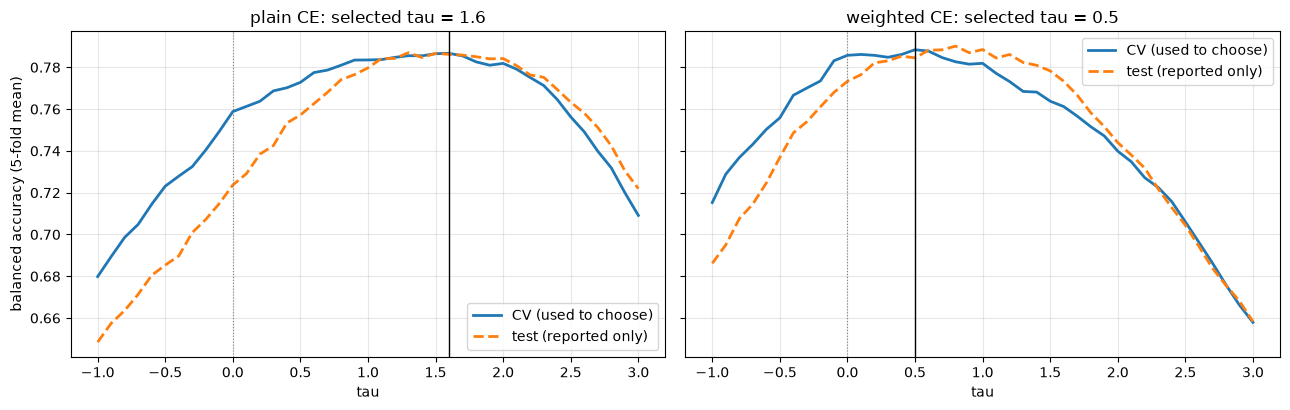

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, r, n in zip(axes, ["resnet50_ce_la", "resnet50_wce_la"], ["plain CE", "weighted CE"]):
    sw = pd.DataFrame(A.tau(r)["sweep"]).set_index("tau")
    ax.plot(sw.index, sw.cv_balanced_acc, lw=2, label="CV (used to choose)")
    ax.plot(sw.index, sw.test_balanced_acc, lw=2, ls="--", label="test (reported only)")
    ax.axvline(A.tau(r)["selected_tau"], c="k", lw=1); ax.axvline(0, c="grey", lw=.8, ls=":")
    ax.set_title(f"{n}: selected tau = {A.tau(r)['selected_tau']}"); ax.set_xlabel("tau"); ax.grid(alpha=.3); ax.legend()
axes[0].set_ylabel("balanced accuracy (5-fold mean)")
plt.tight_layout()

## 3. Where the errors move

,plain CE (baseline),weighted CE,plain CE + logit adjustment,weighted CE + logit adjustment
MEL,0.599,0.674,0.678,0.695
NV,0.931,0.857,0.795,0.780
BCC,0.789,0.794,0.815,0.796
AKIEC,0.730,0.814,0.814,0.819
BKL,0.718,0.742,0.726,0.752
DF,0.618,0.705,0.777,0.759
VASC,0.680,0.829,0.897,0.891


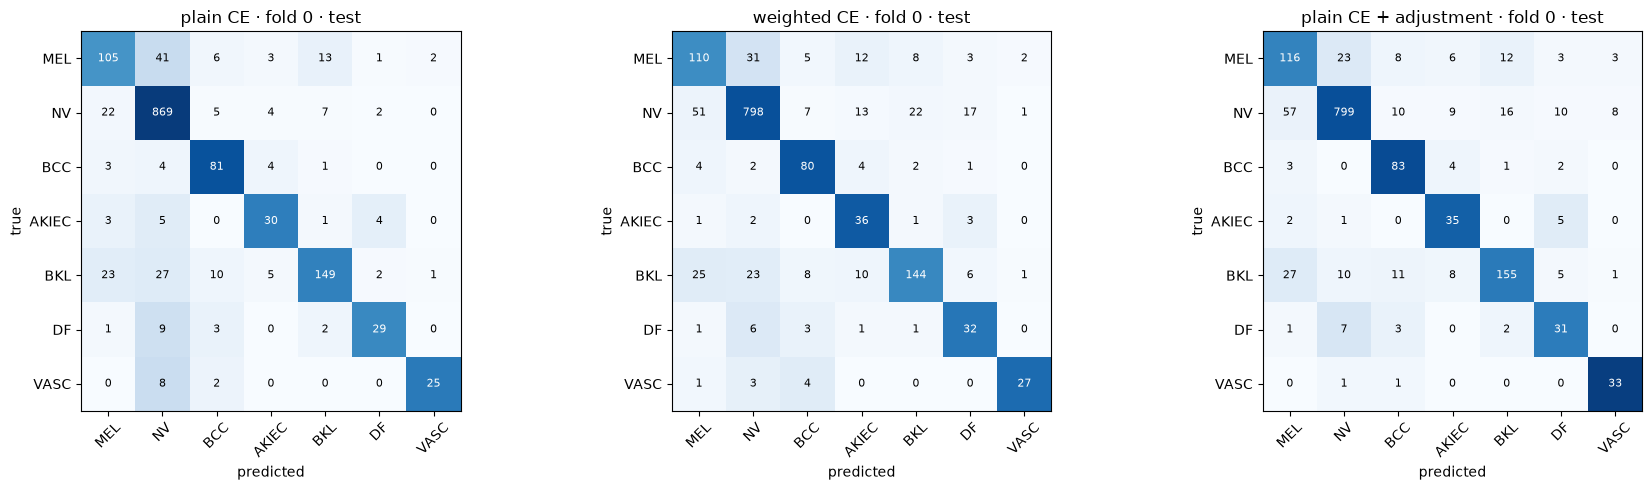

In [6]:
rec = pd.DataFrame({n: A.per_class_recall(r) for r, n in zip(runs, names)})
display(rec.round(3))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, r, n in zip(axes, ["resnet50_ce", "resnet50_wce", "resnet50_ce_la"], ["plain CE", "weighted CE", "plain CE + adjustment"]):
    A.plot_confusion(ax, r, 0, f"{n} · fold 0 · test")
plt.tight_layout()

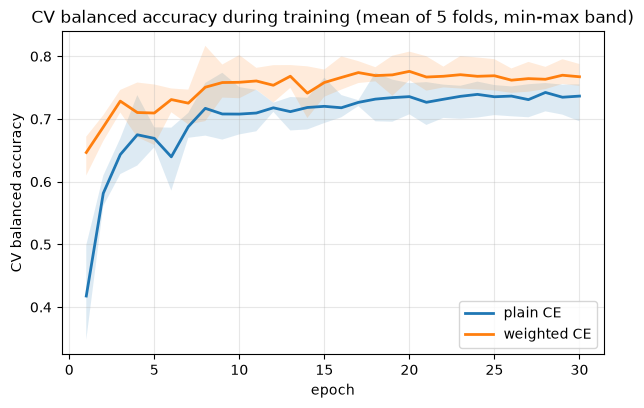

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.2))
A.plot_curves(ax, ["resnet50_ce", "resnet50_wce"], ["plain CE", "weighted CE"])
ax.set_title("CV balanced accuracy during training (mean of 5 folds, min-max band)");

## Takeaways
* **Weighted CE:** 0.724 → 0.773 test balanced accuracy (+0.050, better on 5/5 folds); melanoma sensitivity 0.60 → 0.67.
  AUC is unchanged and accuracy drops 0.024: the model predicts minority classes more often but does not rank images better.
* **Logit adjustment of the plain model, without retraining:** 0.786 (+0.063, 5/5 folds), better than retraining with weights.
* Weighting *plus* adjustment gives 0.785, so imbalance handling plateaus near 0.785 for this model: further gains must
  come from better features (notebook 04).
* The selected τ (1.6) is above the textbook value of 1, a sign the network's probabilities are overconfident.
* The cost is more false alarms: moles flagged as other classes rise, so accuracy and macro-F1 fall.